# Multi-configuration optimization: one lens, several jobs

A zoom lens is one prescription that has to be sharp at every focal length;
a camera lens has to be sharp at infinity and at its closest focus; a
lens may have to work in two wavelength bands, or at −20 °C and at +40 °C.
In each case the *same* radii, thicknesses and glasses serve in several
**configurations** that differ in a few parameters only: the air spaces of
the moving groups, the object distance, the wavelengths, the temperature.
Lens design programs optimize all of them at once: Zemax calls it the
multi-configuration editor, CODE V zoom positions. The merit function is
the sum over the configurations, the variables are shared, and the
parameters that differ are variables (or solves) of their own
configuration.

| section | content |
|---|---|
| 1 | configurations, shared and per configuration variables, the structure of the Jacobian |
| 2 | the smallest case: one singlet for an object at infinity and at 400 mm |
| 3 | a two group zoom, 16 to 30 mm F/5, from the thin lens kinematics |
| 4 | the zoom optimized at all three positions at once |
| 5 | position by position: each position alone, or the middle and then zoom |
| 6 | between the positions: cams, focal length and spots over the whole range |
| 7 | summary |

`pyoptics.lens_optimization.MultiConfiguration` holds the configurations and
`DampedLeastSquares` (notebook 58, lens optimization) optimizes them;
`zoom.ZoomLens` (notebook 127, zoom lenses) holds the zoom spacings.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from pyoptics import lens_optimization as lo
from pyoptics import raytrace as rt
from pyoptics import zoom, sketch
from pyoptics.delano import thick_lens_curvatures
from pyoptics.materials import LAMBDA_F, LAMBDA_C, LAMBDA_d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
POS_COLORS = [RED, GREEN, PURPLE]
WL_F, WL_d, WL_C = LAMBDA_F*1e-6, LAMBDA_d*1e-6, LAMBDA_C*1e-6   # mm
WLS = [WL_F, WL_d, WL_C]
t_start = time.time()

## 1. Configurations

A configuration is a copy of the system with **overrides**. What is
shared and what is not depends on the job:

- **zoom positions**: the air spaces between the moving groups (and the
  back focus), often the F-number and the field;
- **focus**: the object distance, and the position of the focusing group
  (or of the whole lens);
- **wavelength bands**: the wavelengths, with a refocus per band if the
  camera allows it;
- **temperatures**: the indices (dn/dT) and the spacings (expansion of the
  mount), with or without a refocus.

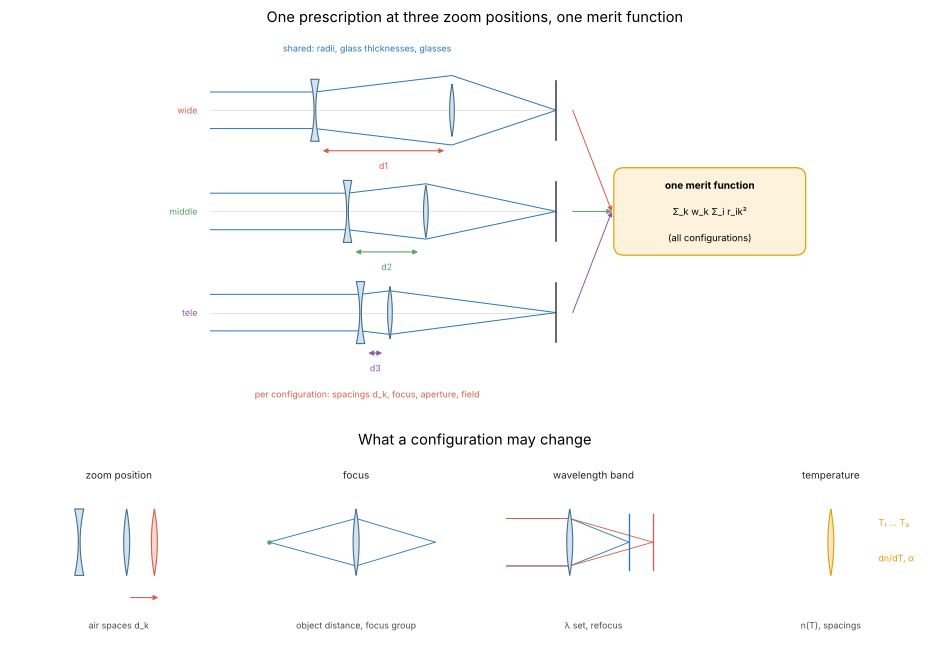

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8.6), gridspec_kw={"height_ratios": [1.6, 1]})
sketch.multiconfig_layout(axes[0], "configurations",
                          title="One prescription at three zoom positions, one merit function")
sketch.multiconfig_layout(axes[1], "overrides", title="What a configuration may change")
fig.tight_layout()

In code, `lo.MultiConfiguration` holds the systems (one per configuration,
built with `lo.configure(system, overrides)` or taken from a
`zoom.ZoomLens`) and goes to `lo.DampedLeastSquares` in place of a single
system. Then

- a plain variable (`lo.Curvature(3)`) is **shared**: it is wrapped in
  `lo.Shared` and sets the same value in every configuration;
- `lo.ConfigVariable(variable, k)` (or `lo.per_configuration(variable, n)`
  for one copy per configuration) changes configuration k only, e.g. the
  zoom spacing of one position;
- a plain operand, solve or constraint is evaluated in every configuration
  and the results are concatenated; `lo.in_configs(f, [k, ...])` restricts
  it to some of them (the focal length of position k, the visible band of
  configuration 0);
- the configurations may carry weights, which multiply their operands
  (not their constraints).

The Jacobian then has a block structure: a shared variable moves the
residuals of every configuration, a spacing of position k only those of
position k. The damped least squares step is the same as for one system,
and the cost per iteration grows with the number of configurations.

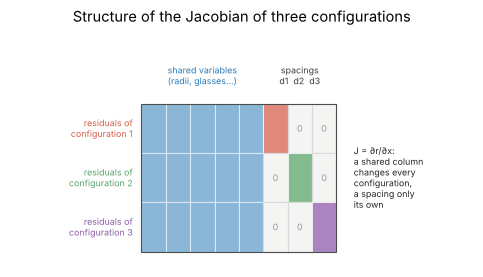

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.6))
sketch.multiconfig_layout(ax, "jacobian", title="Structure of the Jacobian of three configurations")
fig.tight_layout()

## 2. The smallest case: a singlet at two object distances

A singlet of f = 100 mm at F/6.25 focuses an object at infinity and one at
400 mm (the whole lens moves to focus, i.e. the image distance is solved
in each configuration). Its spherical aberration depends on the bending,
the shape factor $X = (c_1 + c_2)/(c_1 - c_2)$, and on the object
position; the bending of least spherical aberration moves towards the
symmetric lens as the object comes closer (the position factor of the
thin lens theory). One bending must serve both.

In [4]:
N_BK7 = lo.GLASSES["N-BK7"]


def singlet(X, object_distance=np.inf, f=100.0, t=4.0):
    c1, c2 = thick_lens_curvatures(1/f, N_BK7[0], t, X)
    S = [rt.Surface(1/c1 if c1 else np.inf, t, material=N_BK7, semi_diameter=8.0),
         rt.Surface(1/c2 if c2 else np.inf, f, n_after=1.0)]
    s = rt.System(S, 0, WL_d, object_distance=object_distance, field_angle=0.0)
    lo.solve_paraxial_focus()(s)
    return s


def shape(s):
    c1, c2 = s.surfaces[0].c, s.surfaces[1].c
    return (c1 + c2)/(c1 - c2)


X = np.linspace(-0.6, 2.0, 105)
W_far = np.array([singlet(x).seidel().W040 for x in X])
W_near = np.array([singlet(x, 400.0).seidel().W040 for x in X])

# DLS: the bending (curvature of surface 0) shared, the focal length and the focus solved
solves = [lo.solve_curvature_for_efl(1, 100.0), lo.solve_paraxial_focus()]
sa = [lo.seidel("W040", 0.0, 1.0)]
results = {}
for name, systems in [("infinity alone", [singlet(0.0)]),
                      ("400 mm alone", [singlet(0.0, 400.0)]),
                      ("both at once", [singlet(0.0), singlet(0.0, 400.0)])]:
    opt = lo.DampedLeastSquares(lo.MultiConfiguration(systems, names=["inf", "400 mm"][:len(systems)]),
                                [lo.Curvature(0)], sa, solves=solves)
    res = opt.run(max_iterations=30)
    results[name] = res
    W = [s.seidel().W040 for s in res.system]
    print("{:15s} X = {:5.3f}   W040 = {}  waves".format(
        name, shape(res.system[0]), ", ".join("{:+.3f}".format(w) for w in W)))
both = results["both at once"].system
print("image distances of the shared lens: {:.3f} mm (infinity), {:.3f} mm (400 mm)".format(
    both[0].surfaces[1].thickness, both[1].surfaces[1].thickness))

infinity alone  X = 0.727   W040 = -1.763  waves
400 mm alone    X = 0.369   W040 = -1.854  waves
both at once    X = 0.542   W040 = -1.827, -1.912  waves
image distances of the shared lens: 97.957 mm (infinity), 131.223 mm (400 mm)


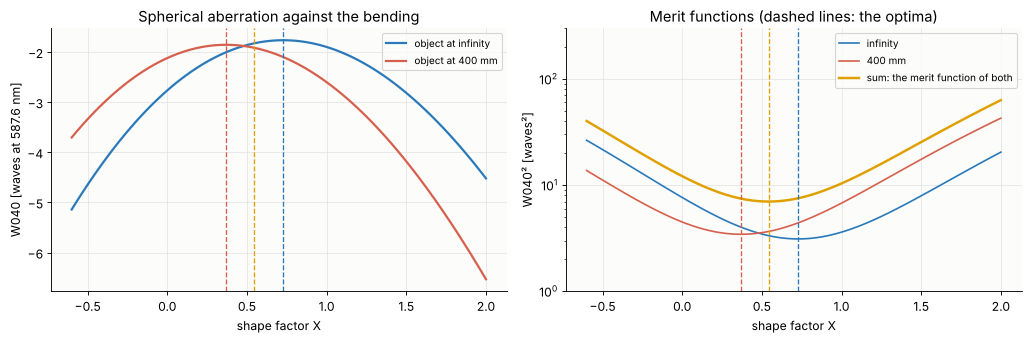

In [5]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.4))
ax0.plot(X, W_far, color=BLUE, lw=2, label="object at infinity")
ax0.plot(X, W_near, color=RED, lw=2, label="object at 400 mm")
for name, col in (("infinity alone", BLUE), ("400 mm alone", RED), ("both at once", ORANGE)):
    x = shape(results[name].system[0])
    ax0.axvline(x, color=col, lw=1.2, ls="--")
ax0.set_xlabel("shape factor X")
ax0.set_ylabel("W040 [waves at 587.6 nm]")
ax0.set_title("Spherical aberration against the bending")
ax0.legend(fontsize=9)
ax1.plot(X, W_far**2, color=BLUE, lw=1.5, label="infinity")
ax1.plot(X, W_near**2, color=RED, lw=1.5, label="400 mm")
ax1.plot(X, W_far**2 + W_near**2, color=ORANGE, lw=2.2, label="sum: the merit function of both")
ax1.set_yscale("log")
ax1.set_ylim(1, 300)
ax1.set_xlabel("shape factor X")
ax1.set_ylabel("W040² [waves²]")
ax1.set_title("Merit functions (dashed lines: the optima)")
for name, col in (("infinity alone", BLUE), ("400 mm alone", RED), ("both at once", ORANGE)):
    ax1.axvline(shape(results[name].system[0]), color=col, lw=1.2, ls="--")
ax1.legend(fontsize=9)
fig.tight_layout()

Alone, the lens for infinity wants X = 0.73 (thin lens theory: 0.74) and the lens for 400 mm X = 0.37. Neither can reach zero: a spherical singlet always has some spherical aberration, here −1.76 and −1.85 waves at F/6.25. The shared bending lands in between, X = 0.54, where both configurations pay a little, −1.83 and −1.91 waves, against 0.24 waves that each would lose with the other's best bending. The image distance is a solve in each configuration: the lens moves by 33.3 mm to focus at 400 mm.

This is the whole idea. The minimum of the sum lies where the gradients of the configurations balance, and a configuration that is hard to correct pulls the shared variables towards itself; the weights of the configurations set the exchange rate.

## 3. A two group zoom

The zoom of section 1 of notebook 127 (zoom lenses): a negative front
group G1 ($f_1$ = −40 mm) and a positive rear group G2 ($f_2$ ≈ 30 mm) at
the separation $d$ give

$$
f = \frac{f_1 f_2}{f_1 + f_2 - d},
$$

and the back focus follows from $d$; both groups move and the image plane
stays. We make it real with five elements:

- G1: a negative meniscus of N-LAK22 and a weak positive meniscus of N-SF2
  (f = +70 mm), the negative one scaled until the group has −40 mm;
- G2: a Cooke triplet (N-SK16, N-F2, N-SK16; the classic f = 50 mm F/5
  design) scaled to f ≈ 30 mm, the aperture stop between the flint and the
  rear crown;
- three positions, f = 16, 22 and 30 mm at F/5, for an image circle of
  7 mm (half fields 12.3° to 6.7°).

The separations and back foci for the three focal lengths come from the
paraxial trace of the thick lens (the thin lens formula is off by the
positions of the principal planes), and the result is a `zoom.ZoomLens`.

In [6]:
G = lo.GLASSES
EFL = np.array([16.0, 22.0, 30.0])
F_NUMBER, IMAGE_HEIGHT = 5.0, 3.5
TRIPLET = [(22.014, 3.259, "N-SK16"), (-435.76, 6.008, None), (-22.213, 1.0, "N-F2"),
           (20.292, 2.0, None), (np.inf, 2.75, None), (79.684, 2.952, "N-SK16")]
STOP = 8          # the stop: G1 has surfaces 0-3, the triplet 4-10
GAP, BACK = 3, 10  # the zoom spacing (G1 to G2) and the back focus


def thin_curvatures(power, n, X):
    dc = power/(n - 1)
    return dc*(X + 1)/2, dc*(X - 1)/2


def radius(c):
    return 1/c if c else np.inf


def start_lens(k_neg, d=20.0, back=40.0, scale=0.6, thick=0.9):
    cn = thin_curvatures(-k_neg/25.0, G["N-LAK22"][0], 1.6)    # negative meniscus
    cp = thin_curvatures(1/70.0, G["N-SF2"][0], -2.0)          # positive meniscus
    S = [rt.Surface(radius(cn[0]), 1.5, material=G["N-LAK22"]),
         rt.Surface(radius(cn[1]), 3.0, n_after=1.0),
         rt.Surface(radius(cp[0]), 3.0, material=G["N-SF2"]),
         rt.Surface(radius(cp[1]), d, n_after=1.0)]
    for R, t, g in TRIPLET:
        S.append(rt.Surface(R*scale, t*thick, material=G[g] if g else None,
                            n_after=None if g else 1.0,
                            semi_diameter=3.0 if np.isinf(R) else None))
    S.append(rt.Surface(-18.395*scale, back, n_after=1.0))
    return rt.System(S, STOP, WL_d, field_angle=np.arctan(IMAGE_HEIGHT/EFL[0]),
                     entrance_pupil_radius=EFL[0]/F_NUMBER/2)


GROUPS = [(0, 3), (4, 10)]


def group_f(s):
    return zoom.ZoomLens(s, {GAP: [s.surfaces[GAP].thickness]}, [1.0],
                         groups=GROUPS).group_focal_lengths(s)


k_neg = brentq(lambda k: 1/group_f(start_lens(k))[0] + 1/40.0, 1.0, 1.5)
base = start_lens(k_neg)


def efl_at(d):
    return lo.configure(base, {GAP: d}).paraxial().efl


gaps = np.array([brentq(lambda d: efl_at(d) - f, 0.1, 150.0) for f in EFL])
backs = np.array([lo.configure(base, {GAP: d, BACK: 0.0}).paraxial().image_distance for d in gaps])
Z0 = zoom.ZoomLens(lo.configure(base, {GAP: gaps[0], BACK: backs[0]}), {GAP: gaps, BACK: backs},
                   EFL, f_numbers=[F_NUMBER]*3, groups=GROUPS)
print("group focal lengths: G1 {:.1f} mm, G2 {:.2f} mm".format(*Z0.group_focal_lengths()))
d_thin, b_thin = zoom.two_group_zoom(-40.0, Z0.group_focal_lengths()[1], EFL)
for k, f in enumerate(EFL):
    print("f = {:4.1f} mm: G1-G2 air space {:6.2f} mm (thin lenses: d = {:5.2f} between the "
          "principal planes), back focus {:5.2f} mm".format(f, gaps[k], d_thin[k], backs[k]))

group focal lengths: G1 -40.0 mm, G2 28.54 mm
f = 16.0 mm: G1-G2 air space  35.30 mm (thin lenses: d = 59.88 between the principal planes), back focus 31.52 mm
f = 22.0 mm: G1-G2 air space  15.84 mm (thin lenses: d = 40.43 between the principal planes), back focus 35.80 mm
f = 30.0 mm: G1-G2 air space   2.00 mm (thin lenses: d = 26.59 between the principal planes), back focus 41.50 mm


f = 16.0 mm  RMS spot (F, d, C) at 0, 0.7, 1 field: [95.2 48.3 80.9] um
f = 22.0 mm  RMS spot (F, d, C) at 0, 0.7, 1 field: [139.4  86.8  74.6] um
f = 30.0 mm  RMS spot (F, d, C) at 0, 0.7, 1 field: [211.4 167.9 132.6] um


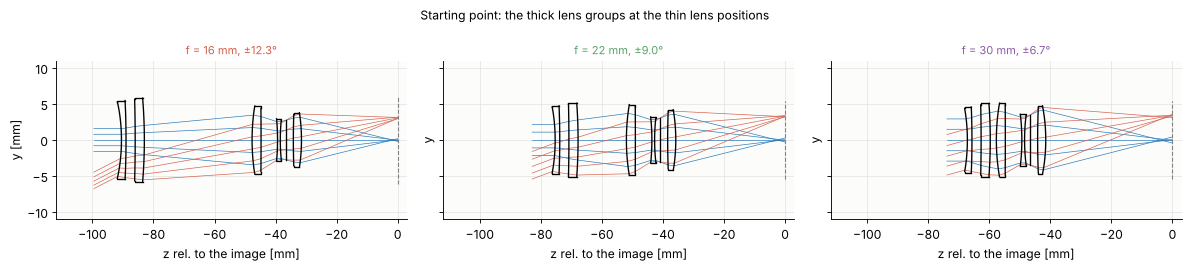

In [7]:
FIELDS = (0.0, 0.7, 1.0)
spot = lo.spot_rms(fields=FIELDS, wavelengths=WLS, tolerance=1e-3)   # polychromatic, in um


def positions(mc_or_zoom):
    if isinstance(mc_or_zoom, zoom.ZoomLens):
        return lo.MultiConfiguration.from_zoom(mc_or_zoom, field_angle=np.arctan(IMAGE_HEIGHT/EFL))
    return mc_or_zoom


def draw_positions(mc, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
    for k, (ax, s) in enumerate(zip(axes, mc)):
        th = s.max_field
        s.draw(ax=ax, fields=[0.0, th], n_rays=5, lw=0.6, colors=[BLUE, RED])
        z0 = s.image_z
        for line in ax.lines:
            line.set_xdata(np.asarray(line.get_xdata()) - z0)
        ax.set_aspect("auto")
        ax.set_xlim(-112, 3)
        ax.set_ylim(-11, 11)
        ax.set_title("f = {:.0f} mm, ±{:.1f}°".format(s.paraxial().efl, np.degrees(th)),
                     fontsize=10, color=POS_COLORS[k])
        ax.set_xlabel("z rel. to the image [mm]")
    axes[0].set_ylabel("y [mm]")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()


mc0 = positions(Z0)
draw_positions(mc0, "Starting point: the thick lens groups at the thin lens positions")
for s in mc0:
    print("f = {:4.1f} mm  RMS spot (F, d, C) at 0, 0.7, 1 field: {} um".format(
        s.paraxial().efl, np.array2string(spot(s), precision=1)))

The start is a sharp lens at no position: 50 to 210 µm RMS. The thin lens kinematics put G1 more than 35 mm in front of G2 at the wide end, and with the principal planes of the thick groups the vertex spacing is 24 mm shorter than the thin lens value. At the long end the groups nearly touch (2 mm), so the zoom ratio of about 1.9 is what this layout gives without the groups colliding.

## 4. All three positions at once

The variables: all ten curvatures, the glass thicknesses and the air
spaces inside the groups, and two aspheres ($r^4$ and $r^6$) on the first
and the last surface, all shared; one G1–G2 spacing per position
(`lo.per_configuration`). Solves in every configuration: the back focus
(paraxial focus) and, per position, the entrance pupil for F/5. The focal
length of each position is a constraint in its own configuration
(`lo.in_configs(..., [k])`), the edge thicknesses of every element are
constraints in all of them. The operand: transverse ray errors at F, d and
C on rings of the pupil at three fields, tolerance 10 µm.

The ray tracer aims the real rays at the stop: the strong negative front
group distorts the entrance pupil at the wide end, and paraxial aiming
would let the rim rays at full field miss.

In [8]:
CURVATURES = [0, 1, 2, 3, 4, 5, 6, 7, 9, 10]
THICKNESSES = [0, 1, 2, 4, 5, 6, 7, 9]
GLASS_ELEMENTS, AIR_GAPS = (0, 2, 4, 6, 9), (1, 5, 7)


def zoom_optimizer(mc, efl, image_positions=None):
    n = len(mc)
    variables = ([lo.Curvature(i) for i in CURVATURES]
                 + [lo.Thickness(i, bounds=(0.8 if i in GLASS_ELEMENTS else 0.3, None))
                    for i in THICKNESSES]
                 + [lo.Aspheric(i, order, 4.0) for i in (0, 10) for order in (4, 6)]
                 + lo.per_configuration(lo.Thickness(GAP, bounds=(0.5, None)), n))
    solves = [lo.solve_paraxial_focus()]
    solves += [lo.in_configs(lo.solve_entrance_pupil(efl[k]/F_NUMBER/2), [k]) for k in range(n)]
    operands = [lo.in_configs(lo.polychromatic_ray_errors(WLS, fields=FIELDS, tolerance=0.01),
                              image_positions)]
    constraints = [lo.Constraint(lo.in_configs(lo.paraxial_value("efl"), [k]), efl[k], efl[k],
                                 1e-3, "efl {:.0f}".format(efl[k])) for k in range(n)]
    constraints += [lo.Constraint(lo.edge_thickness(i), lower=0.8, name="edge {}".format(i))
                    for i in GLASS_ELEMENTS]
    constraints += [lo.Constraint(lo.edge_thickness(i), lower=0.2, name="air edge {}".format(i))
                    for i in AIR_GAPS]
    return lo.DampedLeastSquares(mc, variables, operands, constraints, solves)


opt_all = zoom_optimizer(mc0, EFL)
print("{} variables ({} shared), {} residuals, {} constraint values".format(
    len(opt_all.variables), sum(isinstance(v, lo.Shared) for v in opt_all.variables),
    len(opt_all.residuals()), len(opt_all.constraint_values()[0])))
t0 = time.time()
res_all = opt_all.run(max_iterations=300)
mc_all = res_all.system
print("{} after {} iterations, merit {:.4g} -> {:.4g} ({:.0f} s)".format(
    res_all.message, len(res_all.history) - 1, res_all.history[0]["merit"], res_all.merit,
    time.time() - t0))
print(opt_all.report(["ray errors F, d, C"]))

25 variables (22 shared), 972 residuals, 27 constraint values


maximum number of iterations after 300 iterations, merit 1.686e+05 -> 1767 (608 s)
merit function 1767.24
  ray errors F, d, C                 1767.2   100.0 %
  f = 16                             303.48    17.2 %
  f = 22                             636.77    36.0 %
  f = 30                             826.99    46.8 %
  efl 16                       [16.00001]  [16.0, 16.0]  VIOLATED
  efl 22                       [21.99999]  [22.0, 22.0]  VIOLATED
  efl 30                       [29.99996]  [30.0, 30.0]  VIOLATED
  edge 0                       [5.88936 5.1772  4.95395]  [0.8, None]  ok
  edge 2                       [5.38715 5.64793 5.72097]  [0.8, None]  ok
  edge 4                       [0.94463 0.88685 0.8    ]  [0.8, None]  ok
  edge 6                       [1.64024 1.74959 1.90902]  [0.8, None]  ok
  edge 9                       [1.16316 1.01714 0.8    ]  [0.8, None]  ok
  air edge 1                   [0.2     0.31568 0.35118]  [0.2, None]  ok
  air edge 5                   [3.07

f = 16.0 mm  RMS spot at 0, 0.7, 1 field: [11.2  7.4 12. ] um   G1-G2 48.713 mm, back focus 34.163 mm
f = 22.0 mm  RMS spot at 0, 0.7, 1 field: [14.9 10.3 23.3] um   G1-G2 20.537 mm, back focus 37.347 mm
f = 30.0 mm  RMS spot at 0, 0.7, 1 field: [21.5 12.  22.3] um   G1-G2  0.500 mm, back focus 41.593 mm
System(wavelength=0.0005875618, stop_index=8, object_distance=inf, max_field=0.21535769969773805)
   0  Surface(R=-14.71134908864813, thickness=4.36385100942154, n_after=None, material=(1.65113, 55.89), conic=0.0, aspheric=(np.float64(2.424752904301553e-05), np.float64(2.8891479065477793e-07)), semi_diameter=None) n'=1.651130
   1  Surface(R=-76.42718941534436, thickness=0.44605882661257784, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=None) n'=1.000000
   2  Surface(R=-45.70267641538953, thickness=5.9328646232596345, n_after=None, material=(1.64769, 33.82), conic=0.0, aspheric=(), semi_diameter=None) n'=1.647690
   3  Surface(R=-25.913903860646315, thickness=48.71

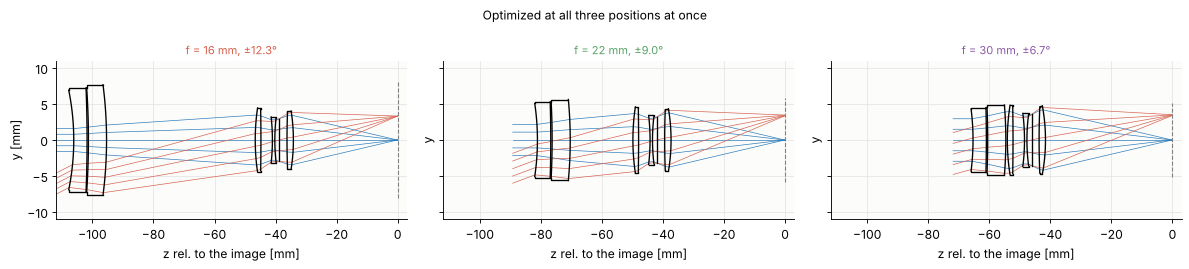

In [9]:
draw_positions(mc_all, "Optimized at all three positions at once")
for s in mc_all:
    print("f = {:4.1f} mm  RMS spot at 0, 0.7, 1 field: {} um   G1-G2 {:6.3f} mm, back focus {:6.3f} mm".format(
        s.paraxial().efl, np.array2string(spot(s), precision=1), s.surfaces[GAP].thickness,
        s.surfaces[BACK].thickness))
print(mc_all[0])

One prescription now gives 7 to 23 µm at all three positions, a factor of 5 to 10 better than the start. The optimizer used all 300 iterations and was still creeping down; in a real design one would now replace the model glasses by catalogue glasses and continue. The spacing at the long end sits on its bound of 0.5 mm: the groups want to come even closer, i.e. the zoom range is limited by the layout, not by the correction. The share of the merit function (17, 36 and 47 % from short to long) shows where the lens struggles: at the long end the aperture of 6 mm in the rear group carries the spherical aberration and the colour of the whole lens.

The constraints show as `VIOLATED` by a few hundredths of a micrometre in the focal length: the run stopped at the iteration limit, not at a converged point where the linearized constraints are exact.

## 5. Position by position

Without configurations, a designer optimizes the image at one position and
hopes for the others. To compare like with like, each position is
optimized alone with the same variables and operands, starting from the
lens of section 4 (the same basin of the merit function). The first order
layout still has to work at all three positions, otherwise the lens would
not zoom from 16 to 30 mm at all (the principal planes of the groups move
when the lens is bent, and the groups would have to overlap at the long
end). This is again a job for the configurations: the focal length
constraints and the spacings stay in all three, the ray errors are
evaluated in one only (`image_positions=[k]`, i.e.
`lo.in_configs(operand, [k])`).

In [10]:
def spot_total(s):
    # RMS over the three fields of the polychromatic RMS spot
    return float(np.sqrt(np.mean(spot(s)**2)))


alone = []
t0 = time.time()
for k in range(3):
    opt_k = zoom_optimizer(mc_all, EFL, image_positions=[k])
    alone.append(opt_k.run(max_iterations=80).system)
print("three single-position optimizations: {:.0f} s".format(time.time() - t0))

designs = {"all at once": mc_all}
for k in range(3):
    designs["image at {:.0f} mm only".format(EFL[k])] = alone[k]
print("RMS spot over the fields [um], used at:   " + "   ".join("f = {:.0f} mm".format(f) for f in EFL))
for name, mc in designs.items():
    print("  {:26s}".format(name) + "".join("{:12.1f}".format(spot_total(s)) for s in mc))

three single-position optimizations: 243 s
RMS spot over the fields [um], used at:   f = 16 mm   f = 22 mm   f = 30 mm
  all at once                       10.4        17.0        19.2
  image at 16 mm only                7.0        17.5        19.6
  image at 22 mm only               26.1        14.0        18.7
  image at 30 mm only               42.2        12.9        17.5


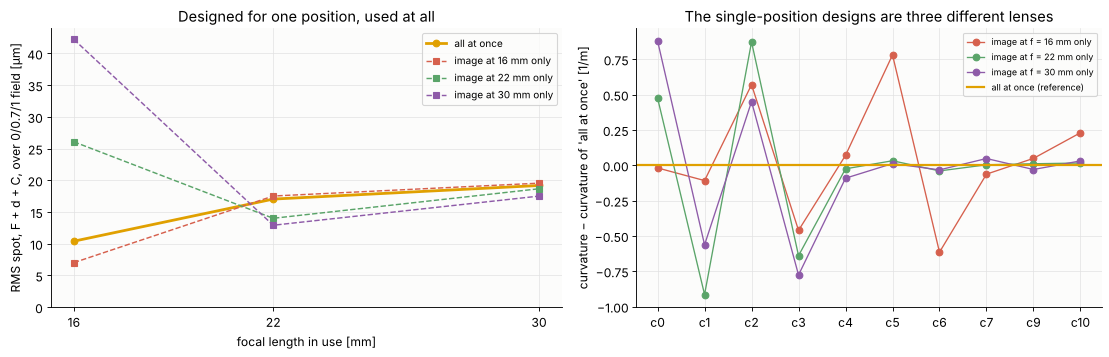

In [11]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
styles = [(ORANGE, "o", "-", 2.5)] + [(c, "s", "--", 1.3) for c in POS_COLORS]
for (name, systems), (col, mk, ls, lw) in zip(designs.items(), styles):
    ax0.plot(EFL, [spot_total(s) for s in systems], marker=mk, color=col, ls=ls, lw=lw, label=name)
ax0.set_xticks(EFL, ["{:.0f}".format(f) for f in EFL])
ax0.set_xlabel("focal length in use [mm]")
ax0.set_ylabel("RMS spot, F + d + C, over 0/0.7/1 field [µm]")
ax0.set_ylim(0, None)
ax0.set_title("Designed for one position, used at all")
ax0.legend(fontsize=9)
c_all = np.array([mc_all[0].surfaces[i].c for i in CURVATURES])
for k, mc in enumerate(alone):
    c = np.array([mc[0].surfaces[i].c for i in CURVATURES])
    ax1.plot(range(len(CURVATURES)), 1e3*(c - c_all), "o-", color=POS_COLORS[k], lw=1.2,
             label="image at f = {:.0f} mm only".format(EFL[k]))
ax1.axhline(0, color=ORANGE, lw=2, label="all at once (reference)")
ax1.set_xticks(range(len(CURVATURES)), ["c{}".format(i) for i in CURVATURES])
ax1.set_ylabel("curvature − curvature of 'all at once' [1/m]")
ax1.set_title("The single-position designs are three different lenses")
ax1.legend(fontsize=8)
fig.tight_layout()

The table and the left plot are the point of multi-configuration optimization:

- **image at one position only**: each single-position design is best where it was optimized (7.0 µm at 16 mm against 10.4 µm, 14.0 against 17.0, 17.5 against 19.2), and it pays elsewhere. The designs for 22 and 30 mm are 2.5 and 4 times worse at the short end than the lens optimized for all positions. The lens designed at the middle position, the obvious choice without configurations, is the second worst at the short end.
- **all at once**: never the best at a single position, and never far from it.

The design for 16 mm alone gains 3.4 µm there and loses only 0.4 to 0.5 µm at the other two positions: the short end costs the others little, and the lens of section 4 is not quite at its minimum yet (its run stopped at 300 iterations, and continuing it would take part of this gain for all positions together).

The right plot shows why the single-position results cannot simply be combined: the curvatures of the three designs differ by up to 0.9 m⁻¹ (radii of 15 to 60 mm change by 0.2 to 3 mm). They are three different lenses, each with its own cams.

## 6. Between the positions

The optimizer has seen three focal lengths. A zoom is used at all the
ones in between, with spacings from the cams. `MultiConfiguration.to_zoom()`
turns the result into a `zoom.ZoomLens` with the optimized spacing table;
its spacings in between are interpolated over log f (a quadratic through
three points, as in notebook 127, zoom lenses). Two questions: how good is
the image between the optimized positions, and how good are interpolated
cams?

largest image shift of the interpolated cam: 9 um, focal length error 0.060 mm
largest RMS spot over the range (refocused): 24.8 um at the full field


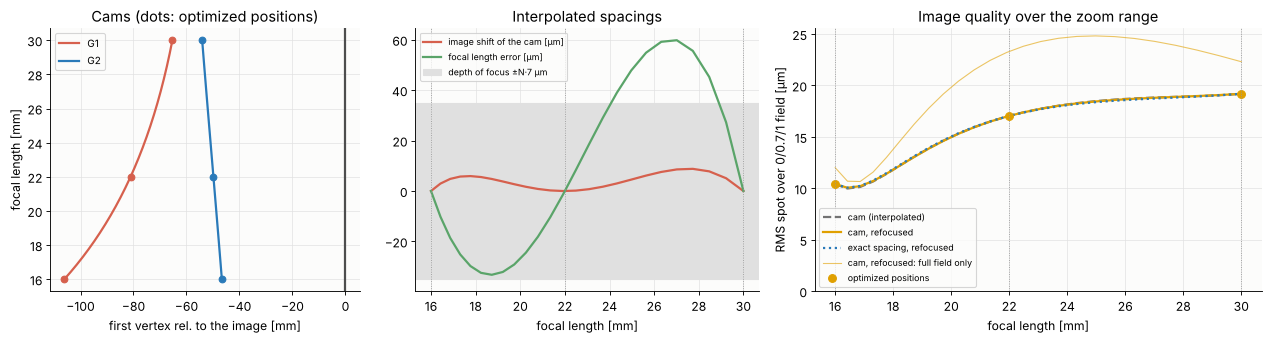

In [12]:
def at_focal_length(system, f):
    # the prescription with the G1-G2 spacing solved for the focal length f, refocused
    d = brentq(lambda d: lo.configure(system, {GAP: d}).paraxial().efl - f, 0.3, 80.0)
    return lo.configure(system, {GAP: d, "max_field": np.arctan(IMAGE_HEIGHT/f),
                                 "entrance_pupil_radius": f/F_NUMBER/2,
                                 "apply": lo.solve_paraxial_focus()})


Z_all = mc_all.to_zoom(Z0)
f_grid = np.geomspace(EFL[0], EFL[-1], 25)
rows = {"cam (interpolated)": [], "cam, refocused": [], "exact spacing, refocused": []}
efl_err, focus_err, pos = [], [], []
for f in f_grid:
    s = Z_all.system(float(f), field_angle=np.arctan(IMAGE_HEIGHT/f))
    p = s.paraxial()
    efl_err.append(p.efl - f)
    focus_err.append(p.image_distance - s.surfaces[BACK].thickness)
    rows["cam (interpolated)"].append(spot(s))
    s_ref = lo.configure(s, {"apply": lo.solve_paraxial_focus()})
    rows["cam, refocused"].append(spot(s_ref))
    rows["exact spacing, refocused"].append(spot(at_focal_length(mc_all[0], f)))
    pos.append(Z_all.group_positions(s_ref))
rows = {k: np.array(v) for k, v in rows.items()}
pos = np.array(pos)

fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(16, 4.4),
                                    gridspec_kw={"width_ratios": [0.9, 1, 1.3]})
for j, (name, col) in enumerate(zip(["G1", "G2"], [RED, BLUE])):
    ax0.plot(pos[:, j], f_grid, color=col, lw=2, label=name)
    ax0.plot([Z_all.group_positions(s)[j] for s in mc_all], EFL, "o", color=col)
ax0.axvline(0, color="0.3", lw=2)
ax0.set_xlabel("first vertex rel. to the image [mm]")
ax0.set_ylabel("focal length [mm]")
ax0.set_title("Cams (dots: optimized positions)")
ax0.legend(fontsize=9)
ax1.plot(f_grid, 1e3*np.array(focus_err), color=RED, lw=2, label="image shift of the cam [µm]")
ax1.plot(f_grid, 1e3*np.array(efl_err), color=GREEN, lw=2, label="focal length error [µm]")
ax1.axhspan(-F_NUMBER*7, F_NUMBER*7, color="0.88", label="depth of focus ±N·7 µm")
for f in EFL:
    ax1.axvline(f, color="0.6", lw=0.8, ls=":")
ax1.set_xlabel("focal length [mm]")
ax1.set_title("Interpolated spacings")
ax1.legend(fontsize=8)
for name, (col, ls) in zip(rows, [(GREY, "--"), (ORANGE, "-"), (BLUE, ":")]):
    ax2.plot(f_grid, np.sqrt(np.mean(rows[name]**2, axis=1)), color=col, ls=ls, lw=2, label=name)
ax2.plot(f_grid, rows["cam, refocused"][:, 2], color=ORANGE, ls="-", lw=1, alpha=0.6,
         label="cam, refocused: full field only")
ax2.plot(EFL, [spot_total(s) for s in mc_all], "o", color=ORANGE, ms=7, label="optimized positions")
for f in EFL:
    ax2.axvline(f, color="0.6", lw=0.8, ls=":")
ax2.set_ylim(0, None)
ax2.set_xlabel("focal length [mm]")
ax2.set_ylabel("RMS spot over 0/0.7/1 field [µm]")
ax2.set_title("Image quality over the zoom range")
ax2.legend(fontsize=8)
fig.tight_layout()
print("largest image shift of the interpolated cam: {:.0f} um, focal length error {:.3f} mm".format(
    1e3*np.max(np.abs(focus_err)), np.max(np.abs(efl_err))))
print("largest RMS spot over the range (refocused): {:.1f} um at the full field".format(
    rows["cam, refocused"][:, 2].max()))

The quadratic interpolation of three spacings over log f is good enough for this simple lens: the image moves by at most 9 µm between the optimized positions, a third of the depth of focus at F/5 for 7 µm blur, and the focal length is off by at most 60 µm. Refocusing changes nothing visible, and the spot with the interpolated cam is the same as with the spacing solved exactly for the focal length. (The four-group zoom of notebook 127 (zoom lenses) is very different: there the interpolated cam is 0.8 mm off.)

The image quality between the optimized positions varies smoothly, 10 µm near the short end to 19 µm at the long end, with no dips: three positions were enough here. A zoom with a large ratio, or one whose aberrations change quickly with the position (the full field curve rises fast from 16 to 20 mm), needs more configurations, typically 5 to 9 in practice, at the cost of a proportionally slower Jacobian.

## 7. Summary

- A **configuration** is a copy of the lens with overrides: zoom spacings, object distance, wavelengths, temperature. `lo.MultiConfiguration` holds them (from overrides with `lo.configure()`, or from a `zoom.ZoomLens` with `from_zoom()`), and `lo.DampedLeastSquares` optimizes them together.
- Plain variables are **shared**; `lo.ConfigVariable` and `lo.per_configuration()` give each configuration its own copy (the zoom spacings). Operands, solves and constraints are evaluated in every configuration unless `lo.in_configs()` restricts them; configuration weights multiply the operands.
- The **Jacobian** has the shared columns full and the per-configuration columns block diagonal; the damped least squares step is the same as for one system.
- A singlet for two object distances settles on a bending between the two best ones. A five element two group zoom (16 to 30 mm F/5, two aspheres) gets 7 to 23 µm RMS at all three positions from one prescription, where single-position designs are better by up to a third at their own focal length and up to four times worse at the others.
- `MultiConfiguration.to_zoom()` turns the result back into a `zoom.ZoomLens`, whose cams interpolate the spacings between the optimized positions; here the image moves by less than 10 µm and the spot varies smoothly between them.

The same machinery serves the later lens design topics: athermal lenses (temperatures as configurations, once the glasses carry dn/dT), the field positions of off-axis mirror systems and the scan positions of scan lenses (notebook 149, scan lenses). `LensOptimizer` accepts `configurations=` with shared variables as well.

In [13]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 855 s
